In [1]:
%pip install pandas
%pip install spacy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install -q spacy
!python -m spacy download en_core_web_sm


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
      --------------------------------------- 0.3/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.6/12.8 MB 13.1 MB/s eta 0:00:01
     ------ --------------------------------- 2.1/12.8 MB 4.3 MB/s eta 0:00:03
     ------------------ --------------------- 6.0/12.8 MB 9.1 MB/s eta 0:00:01
     ------------------------------ --------- 9.7/12.8 MB 11.6 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 12.0 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import spacy
import re
import html
from spacy.lang.en.stop_words import STOP_WORDS
from matplotlib.patches import Patch
import sys
sys.path.append("../src")

In [4]:
#from cargar_dataset import cargar
train_df = pd.read_csv("../data/ag_news/ag_news_train.csv")
test_df = pd.read_csv("../data/ag_news/ag_news_test.csv")
print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Clases:", sorted(train_df["label"].unique()))
train_df.head()

Train: (8000, 2) | Test: (2000, 2)
Clases: ['Business', 'Sci_Tech', 'Sports', 'World']


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,Sports


In [5]:
nlp = spacy.load("en_core_web_sm")
doc = nlp("The cats are running quickly")
print([(t.text, t.lemma_) for t in doc])

[('The', 'the'), ('cats', 'cat'), ('are', 'be'), ('running', 'run'), ('quickly', 'quickly')]


In [6]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])


def limpiar_texto(text):
    text = html.unescape(str(text))                                   # entidades HTML
    text = re.sub(r"<[^>]+>", " ", text)                              # tags HTML
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)                # URLs
    text = re.sub(r"quote,?\s+profile,?\s+research|canadian\s+press|associated\s+press", " ", text, flags=re.I)  # firmas de agencia
    text = re.sub(r"\b(reuters|afp|ap)\b", " ", text, flags=re.I)     # firmas de agencia
    text = re.sub(r"\b(quot|amp|lt|gt);|#\d+;", " ", text, flags=re.I)  # restos de entidades
    text = text.lower()                                               # minúsculas
    text = re.sub(r"\b[\w-]+(?:\.[\w-]+)*\.(?:com|net|org|edu|gov|biz|info)\b", " ", text, flags=re.I)  # dominios web
    text = re.sub(r"[^a-z\s]", " ", text)                             # números, puntuación, símbolos
    return re.sub(r"\s+", " ", text).strip()

def lematizar(texto_limpio):
    doc = nlp(texto_limpio)
    return " ".join(t.lemma_ for t in doc if t.is_alpha and not t.is_stop and len(t) > 1)


def preprocess_text(text):
    return lematizar(limpiar_texto(text))

In [7]:
train_df["clean"] = train_df["text"].apply(limpiar_texto)      # limpio, CON stop-words
train_df["processed"] = train_df["clean"].apply(lematizar)     # lematizado, SIN stop-words
train_df[["text", "processed"]].head()

,text,processed
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoint new cfo september web host ind...
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc hotspot roam deal sprint sbc commun...
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage ground west coast flights airport...
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuit strike net pirate hollywood ...
4,Custis Takes Control. Family and Tony Robbins ...,custis take control family tony robbin mature ...


Percentil 95: 32


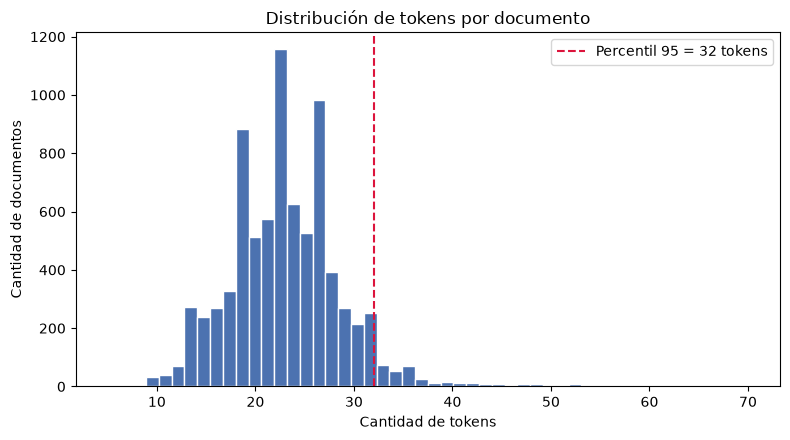

In [8]:
train_df["n_tokens"] = train_df["processed"].str.split().str.len()
p95 = int(np.percentile(train_df["n_tokens"], 95))
print("Percentil 95:", p95)

plt.figure(figsize=(8, 4.5))
plt.hist(train_df["n_tokens"], bins=50, color="#4C72B0", edgecolor="white")
plt.axvline(p95, color="crimson", linestyle="--", label=f"Percentil 95 = {p95} tokens")
plt.title("Distribución de tokens por documento")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Cantidad de documentos")
plt.legend()
plt.tight_layout()
plt.savefig("../reports/figures/hist_tokens.png", dpi=200)
plt.show()

In [9]:
train_df["n_tokens"].describe()

count    8000.00000
mean       23.04575
std         5.86116
min         5.00000
25%        19.00000
50%        23.00000
75%        26.00000
max        70.00000
Name: n_tokens, dtype: float64

In [10]:
def top_ngramas(textos, n, k=20):
    vec = CountVectorizer(ngram_range=(n, n))
    X = vec.fit_transform(textos)
    frecs = np.asarray(X.sum(axis=0)).ravel()
    nombres = vec.get_feature_names_out()
    orden = frecs.argsort()[::-1][:k]
    return pd.DataFrame({f"{n}-grama": nombres[orden], "frecuencia": frecs[orden]})


top_bi = top_ngramas(train_df["processed"], 2)
top_tri = top_ngramas(train_df["processed"], 3)
display(top_bi)
display(top_tri)

,2-grama,frecuencia
0,new york,419
1,oil price,197
2,united states,167
3,prime minister,139
4,official say,115
5,say thursday,102
6,say monday,101
7,say tuesday,98
8,red sox,98
9,los angeles,96


,3-grama,frecuencia
0,new york stock,37
1,boston red sox,37
2,high oil price,27
3,prime minister ariel,26
4,minister ariel sharon,25
5,secretary state colin,22
6,state colin powell,22
7,president vladimir putin,21
8,new york yankees,21
9,president george bush,21


In [11]:
vec = CountVectorizer(token_pattern=r"[a-z]{2,}")
X = vec.fit_transform(train_df["clean"])
frecs = np.asarray(X.sum(axis=0)).ravel()
palabras = vec.get_feature_names_out()
orden = frecs.argsort()[::-1][:50]

top50 = pd.DataFrame({"palabra": palabras[orden], "frecuencia": frecs[orden]})
top50["es_stopword"] = top50["palabra"].isin(STOP_WORDS)
display(top50)
print(f"De las 50 palabras más frecuentes, {top50['es_stopword'].sum()} son stop-words")

,palabra,frecuencia,es_stopword
0,the,13698,True
1,to,7975,True
2,of,6578,True
3,in,6363,True
4,and,4637,True
5,on,3773,True
6,for,3410,True
7,that,1929,True
8,with,1771,True
9,as,1720,True


De las 50 palabras más frecuentes, 39 son stop-words


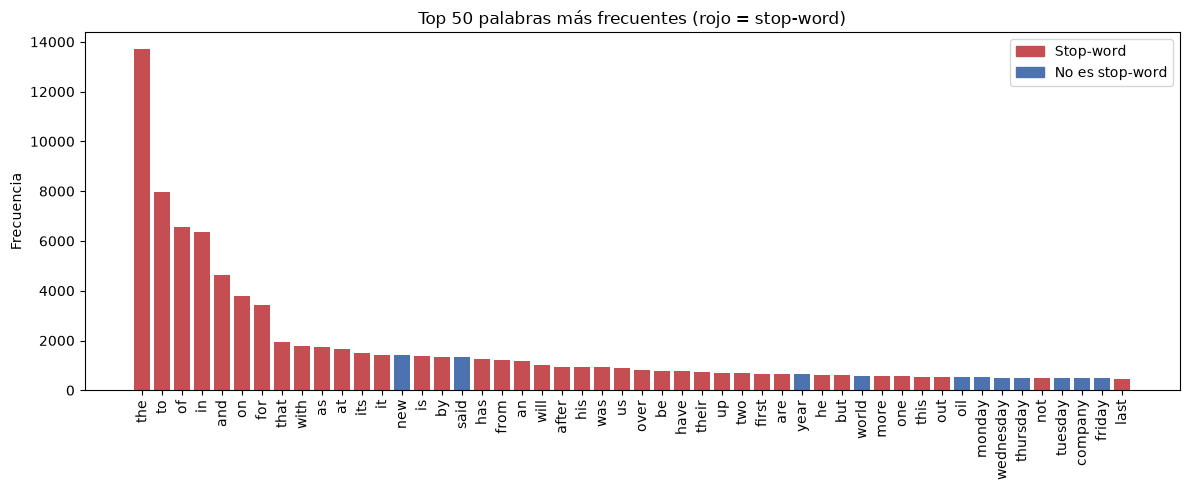

In [12]:
colores = ["#C44E52" if s else "#4C72B0" for s in top50["es_stopword"]]
plt.figure(figsize=(12, 5))
plt.bar(top50["palabra"], top50["frecuencia"], color=colores)
plt.xticks(rotation=90)
plt.title("Top 50 palabras más frecuentes (rojo = stop-word)")
plt.ylabel("Frecuencia")
plt.legend(handles=[Patch(color="#C44E52", label="Stop-word"), Patch(color="#4C72B0", label="No es stop-word")])
plt.tight_layout()
plt.savefig("../reports/figures/top50.png", dpi=200)
plt.show()

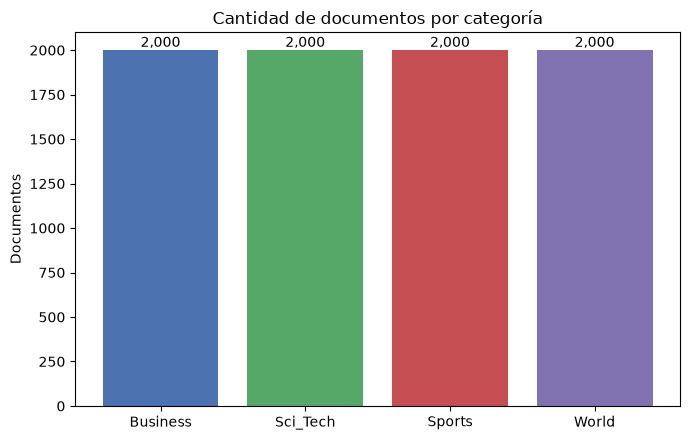

label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64


In [13]:
conteo = train_df["label"].value_counts().sort_index()

plt.figure(figsize=(7, 4.5))
barras = plt.bar(conteo.index, conteo.values, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
for b, v in zip(barras, conteo.values):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:,}", ha="center", va="bottom")
plt.title("Cantidad de documentos por categoría")
plt.ylabel("Documentos")
plt.tight_layout()
plt.savefig("../reports/figures/clases.png", dpi=200)
plt.show()
print(conteo)